(ro_medical_scheduling:title)= 
# Robust Medical Appointment Scheduling

In this example, we consider a medical appointment scheduling problem studied introduced in {cite:ps}`Bertsimas_Sim_Zhang2019adaptive`, where $N$ patients arrive at their stipulated schedule and may have to wait in a queue to be served by a physician. The patients' consultation times are uncertain and their arrival schedules are determined at the first stage, which can influence the waiting times of the patients and the overtime of the physician. 

Consider $\pmb{x}\in\mathbb{R}_+^N$ as the first-stage decision, indicating the assigned lengths of consultation allocated to each patient. All appointments must be scheduled within the physician's regular working hours, denoted by $T$, thus the constraint $\sum_{i=1}^Nx_i \leq T$. Let $\pmb{z}\in\mathbb{R}^N$ be the actual lengths of consultation time. The total cost of the physician is expressed as the recourse problem $Q(\pmb{x}, \pmb{z})$:

```{math}
\begin{aligned}
Q(\pmb{x}, \pmb{z}) = \min~&\sum\limits_{i=1}^Ny_i + cy_{N+1} \\
\text{s.t.}~&y_{i+1} \geq y_i + z_i - x_i &&\forall i \in [N] \\
&\pmb{y}\in\mathbb{R}_+^{N+1},
\end{aligned}
```

where $y_i$ with $i\in[N]$ represents the adaptive decision indicating the waiting time of the $i$th patient, and $y_{N+1}$ is the overtime of the physician. The parameter $c$ denotes the unit cost of physician overtime. 

According to {cite:ps}`Bertsimas_Shtern_Surt2022two`, parameters of the medical appointment problem are

- $N=8$ as the number of patients;
- $c=2.0$ as the unit cost of physician overtime;
- $\pmb{\mu}=\mathbb{R}^N$ as the mean consultation time of all patients, each $\mu_i$ is randomly generated uniformly over $[30,~60]$;
- $\pmb{\sigma}\in\mathbb{R}^N$ as the standard deviations of the consultation times, each $\sigma_i$ is randomly generated uniformly over $[0,~0.3]$;
- $T$ as the regular working hours of the physician, expressed as $T=\sum_{i=1}^N\mu_i + 0.5\sqrt{\sum_{i=1}^N\sigma_i^2}$.

These parameters are defined in the code segment below.

In [1]:
import numpy as np

N = 8                                         # N as the total number of patients
c = 2                                         # c as the unit cost of overtime

np.random.seed(1)
mu = 30 + 30*np.random.rand(N)                # mu as the mean consultation time
sigma = mu * 0.3*np.random.rand(N)            # sigma as the standard deviation
T = mu.sum() + 0.5*((sigma**2).sum())**0.5    # T as the regular working hours of the physician

It is assumed that for the decision-maker, the exact information on the mean and standard deviation of the consultation time is unknown, the distribution of the consultation time is represented by a randomly generated dataset of $S=64$ records with a mean value of $\pmb{\mu}$ and a standard deviation of $\pmb{\sigma}$.

In [2]:
S = 64
zhat = mu + sigma*np.random.normal(size=(S, N))

In the forthcoming numerical studies, we will illustrate the application of RSOME in formulating and solving the appointment scheduling problem using various data-driven robust models.

## Robust Optimization with Budgeted Uncertainty Set

The medical appointment problem is firstly formulated as a robust optimization model

```{math}
\begin{aligned}
\min~&\max\limits_{\pmb{z}\in\mathcal{Z}}Q(\pmb{x}, \pmb{z}) \\
\text{s.t.}~&\sum\limits_{i=1}^Nx_i\leq T \\
&\pmb{x}\in\mathbb{R}_+^N,
\end{aligned}
```

where the uncertainty set $\mathcal{Z}$ is expressed as:

```{math}
\mathcal{Z} = \left\{
\pmb{z}: \underline{\pmb{z}} \leq \pmb{z} \leq \overline{\pmb{z}},~\sum\limits_{i=1}^Nz_i \leq \Gamma 
\right\},
```

where the lower bound $\underline{\pmb{z}}$, upper bound $\overline{\pmb{z}}$, and the budget of uncertainty $\Gamma$, are determined in a data-driven manner, as the code below.

In [3]:
zlb = zhat.min(axis=0)
zub = zhat.max(axis=0)
Gamma = zhat.sum(axis=1).max()
Gamma

348.4237443354999

Such a robust model is solved by the following code.

In [4]:
from rsome import ro

model = ro.Model()                                # define a DRO model
z = model.rvar(N)                                 # random variable z
zset = (zlb <= z, z <= zub,
        z.sum() <= Gamma)                         # a budgeted uncertainty set

x = model.dvar(N)                                 # the here-and-now decision
y = model.dvar(N+1)                                # the wait-and-see decision
y.adapt(z)                                        # define affine adaptation

model.minmax(y[:-1].sum() + c*y[-1], zset)        # worst-case expected cost
model.st(y[1:] - y[:-1] + x >= z)                 # constraints
model.st(y >= 0)                                  # constraints
model.st(0 <= x, x.sum() <= T)                    # constraints

model.solve()                                     # solve the model

Being solved by the Scipy LP solver...
Solution status: 0
Running time: 0.0185s


In [5]:
x_ro = x.get()
print(f'Objective: {model.get():.4f}')

Objective: 197.7891


## Sample Robust Optimization with Single-Policy Approximation

In this section, we will adopt the sample robust optimization (SRO) approach proposed by {cite:ps}`Bertsimas_Shtern_Surt2022two`, which formulate the medical appointment problem as

```{math}
\begin{aligned}
\min~& \frac{1}{S}\sum\limits_{s=1}^Sv_s \\
\text{s.t.}~&Q(\pmb{x}, \pmb{z}) \leq v_s &&\forall \pmb{z}\in\mathcal{Z}_s, ~\forall s \in [S]\\
&\sum\limits_{i=1}^Nx_i\leq T \\
&\pmb{v}\in\mathbb{R}^S,~\pmb{x}\in\mathbb{R}_+^N,
\end{aligned}
```

with each uncertainty set $\mathcal{Z}_s$ being an Euclidean ball centered at each sample records $\hat{\pmb{z}}_s$:

```{math}
\mathcal{Z}_s = \left\{
\pmb{z}: \|\pmb{z} - \hat{\pmb{z}}\| \leq \epsilon
\right\},
```

where $\epsilon$ is a parameter that controlling the size of the uncertainty size. In the following code that formulates and solves the SRO model, $\epsilon$ is selected to be $S^{-1/8}$.

In [6]:
from rsome import ro
import rsome as rso

epsilon = S**(-1/8)

model = ro.Model()
z = model.rvar(N)

x = model.dvar(N)
v = model.dvar(S)
y = model.dvar(N+1)
y.adapt(z)

model.min((1/S)*v.sum())
for s in range(S):
    zset = rso.norm((1/sigma)*(z - zhat[s])) <= epsilon
    model.st((y[:-1].sum() + c*y[-1] <= v[s]).forall(zset))
    model.st((y[1:] - y[:-1] + x >= z).forall(zset))
    model.st((y >= 0).forall(zset))

model.st(0 <= x, x.sum() <= T)

model.solve()

Being solved by ECOS 2.0.14...
Solution status: Optimal solution found
Running time: 0.2529s


In [7]:
x_sp = x.get()
print(f'Objective: {model.get():.4f}')

Objective: 135.8208


Note that the worst-case values of the $Q(\pmb{x}, \pmb{z})$ are expressed over different uncertainty sets $\mathcal{Z}_s$. These different uncertainty sets can be specified via the `forall()` method of constraints involving random variables. 

## Sample Robust Optimization with Multiple-Policy Approximation

In previous numerical experiments, the adaptive decision $\pmb{y}(\pmb{z})$ is approximated by a linear decision rule $\mathcal{L}([N])$, implying that $\pmb{y}(\pmb{z})$ is an affine function of $\pmb{z}$. {cite:ps}`Bertsimas_Shtern_Surt2022two` also proposed a multiple-policy where the adaptive decision $\pmb{y}(\pmb{z})$ can be different affine functions of $\pmb{z}$ under various sample records. The adaptive decision `y` in the following code is therefore defined for each sample record, and the constraints for each sample record are imposed to `y[s]`.

In [8]:
from rsome import ro
import rsome as rso

epsilon = S**(-1/8)

model = ro.Model()
z = model.rvar(N)

x = model.dvar(N)
v = model.dvar(S)
y = model.dvar((S, N+1))
y.adapt(z)

model.min((1/S)*v.sum())
for s in range(S):
    zset = rso.norm((1/sigma)*(z - zhat[s])) <= epsilon
    model.st((y[s, :-1].sum() + c*y[s, -1] <= v[s]).forall(zset))
    model.st((y[s, 1:] - y[s, :-1] + x >= z).forall(zset))
    model.st((y[s] >= 0).forall(zset))

model.st(0 <= x, x.sum() <= T)

model.solve()

Being solved by ECOS 2.0.14...
Solution status: Optimal solution found
Running time: 0.2094s


In [9]:
x_mp = x.get()
print(f'Objective: {model.get():.4f}')

Objective: 64.7996


## Visualization of the Optimal Schedules

Finally, the optimal decisions yielded from the RO model, the SRO model with SP and MP adaptation schemes are visualized as follows.

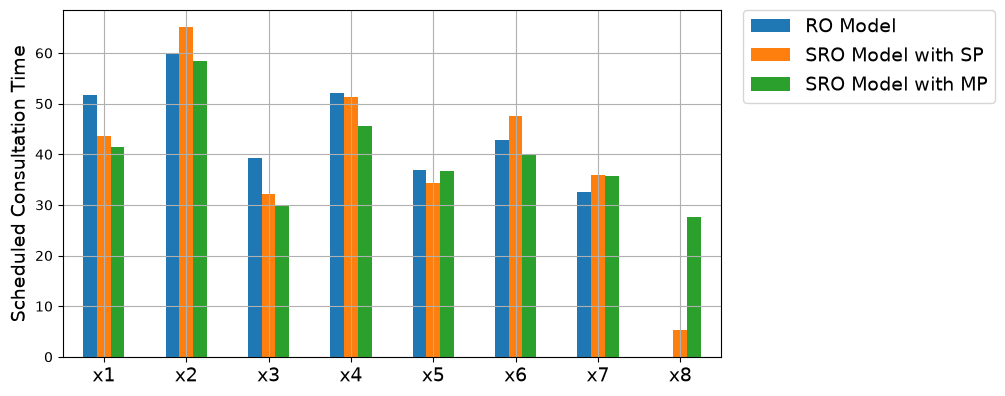

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({'RO Model': x_ro,
                        'SRO Model with SP': x_sp,
                        'SRO Model with MP': x_mp})

fig, ax = plt.subplots(1, 1, figsize=(8.5, 4.5))
results.plot(kind='bar', ax=ax)
plt.ylabel('Scheduled Consultation Time', fontsize=14)
plt.xticks(np.arange(N), [f'x{i+1}' for i in range(N)],
           fontsize=14, rotation=0)
plt.legend(fontsize=14, bbox_to_anchor=(1.43, 1.03))
plt.grid()
plt.show()

<br>
<br>

<font size="5">Reference</font>

```{bibliography}
:filter: docname in docnames
```